<a href="https://colab.research.google.com/github/PavanRishi69/Interpretable-Wind-Power-Forecasting/blob/main/Interpretable_Wind_Power_Forecasting_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Interpretable Wind Power Forecasting

## Short-Horizon Wind Power Prediction Using Random Forest

**Dataset:** Kelmarsh Wind Farm SCADA 2020

**Turbine:** Kelmarsh Turbine 1

**Forecast Horizon:** 30 minutes

**Models:**
- Persistence Baseline
- Random Forest Regressor

**Data Split:**
- Training: 60%
- Validation: 20%
- Testing: 20%

**Evaluation Metrics:**
- MAE
- RMSE
- R²

**Objective:**
Predict wind turbine power 30 minutes ahead
and compare Random Forest with a persistence baseline.

In [1]:
from google.colab import files
import os

# Upload the Kelmarsh 2020 SCADA ZIP dataset
uploaded = files.upload()

ZIP_PATH = "/content/Kelmarsh_SCADA_2020_3086.zip"

print("Uploaded files:", list(uploaded.keys()))
print("ZIP file exists:", os.path.exists(ZIP_PATH))

Saving Kelmarsh_SCADA_2020_3086.zip to Kelmarsh_SCADA_2020_3086.zip
Uploaded files: ['Kelmarsh_SCADA_2020_3086.zip']
ZIP file exists: True


In [2]:
import zipfile
import pandas as pd

# Kelmarsh 2020 SCADA dataset
ZIP_PATH = "/content/Kelmarsh_SCADA_2020_3086.zip"

# Select Turbine 1 data
CSV_FILE = "Turbine_Data_Kelmarsh_1_2020-01-01_-_2021-01-01_228.csv"

# Read CSV directly from ZIP
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    with z.open(CSV_FILE) as f:
        df = pd.read_csv(f, skiprows=9)

# Check dataset
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df[[
    "# Date and time",
    "Power (kW)",
    "Wind speed (m/s)",
    "Wind direction (°)"
]].head())

Dataset loaded successfully!
Dataset shape: (52704, 299)


,# Date and time,Power (kW),Wind speed (m/s),Wind direction (°)
0,2020-01-01 00:00:00,150.984141,3.887291,116.839462
1,2020-01-01 00:10:00,130.414782,3.848941,115.659361
2,2020-01-01 00:20:00,146.401656,4.043625,116.646515
3,2020-01-01 00:30:00,84.296224,3.330342,111.157642
4,2020-01-01 00:40:00,94.994105,3.388536,116.678227


## Step 4: Data Preprocessing and Target Creation

Convert timestamps, sort the observations chronologically, check the 10-minute sampling interval, and create the 30-minute-ahead power forecasting target.

In [3]:
import numpy as np

# Select only the required measurements
work = df[[
    "# Date and time",
    "Power (kW)",
    "Wind speed (m/s)",
    "Wind direction (°)"
]].copy()

# Convert timestamps
work["# Date and time"] = pd.to_datetime(
    work["# Date and time"]
)

# Convert measurements to numeric values
numeric_columns = [
    "Power (kW)",
    "Wind speed (m/s)",
    "Wind direction (°)"
]

for col in numeric_columns:
    work[col] = pd.to_numeric(work[col], errors="coerce")

# Sort chronologically and remove duplicate timestamps
work = (
    work.sort_values("# Date and time")
        .drop_duplicates(subset="# Date and time")
        .reset_index(drop=True)
)

# Check time intervals
time_diff = work["# Date and time"].diff()

print("Time interval counts:")
print(time_diff.value_counts().head())

# Create target: 3 x 10 minutes = 30 minutes ahead
work["Target_Power_30min"] = work["Power (kW)"].shift(-3)

# Display results
print("\nRows after timestamp cleaning:", len(work))
print("Missing values:")
print(work[numeric_columns + ["Target_Power_30min"]].isna().sum())

display(work.head())

Time interval counts:
# Date and time
0 days 00:10:00    52703
Name: count, dtype: int64

Rows after timestamp cleaning: 52704
Missing values:
Power (kW)            468
Wind speed (m/s)      468
Wind direction (°)    468
Target_Power_30min    471
dtype: int64


,# Date and time,Power (kW),Wind speed (m/s),Wind direction (°),Target_Power_30min
0,2020-01-01 00:00:00,150.984141,3.887291,116.839462,84.296224
1,2020-01-01 00:10:00,130.414782,3.848941,115.659361,94.994105
2,2020-01-01 00:20:00,146.401656,4.043625,116.646515,262.992229
3,2020-01-01 00:30:00,84.296224,3.330342,111.157642,449.115810
4,2020-01-01 00:40:00,94.994105,3.388536,116.678227,456.427864


## Step 5: Feature Engineering

Create cyclical time features to represent daily and seasonal patterns. The final model uses seven features: current power, wind speed, wind direction, hour sine/cosine, and day-of-year sine/cosine.

In [4]:
# Extract hour and day of year from timestamps
work["hour"] = work["# Date and time"].dt.hour
work["day_of_year"] = work["# Date and time"].dt.dayofyear

# Cyclical hour features
work["hour_sin"] = np.sin(2 * np.pi * work["hour"] / 24)
work["hour_cos"] = np.cos(2 * np.pi * work["hour"] / 24)

# Cyclical annual features
work["dayofyear_sin"] = np.sin(
    2 * np.pi * work["day_of_year"] / 365.25
)

work["dayofyear_cos"] = np.cos(
    2 * np.pi * work["day_of_year"] / 365.25
)

# Final input features
features = [
    "Power (kW)",
    "Wind speed (m/s)",
    "Wind direction (°)",
    "hour_sin",
    "hour_cos",
    "dayofyear_sin",
    "dayofyear_cos"
]

# Remove rows with missing input or target values
model_data = work.dropna(
    subset=features + ["Target_Power_30min"]
).copy()

# Prepare input features and prediction target
X = model_data[features]
y = model_data["Target_Power_30min"]

print("Usable observations:", len(model_data))
print("Number of input features:", X.shape[1])
print("Missing values remaining:", model_data[features + ["Target_Power_30min"]].isna().sum().sum())

display(X.head())

Usable observations: 52170
Number of input features: 7
Missing values remaining: 0


,Power (kW),Wind speed (m/s),Wind direction (°),hour_sin,hour_cos,dayofyear_sin,dayofyear_cos
0,150.984141,3.887291,116.839462,0.0,1.0,0.017202,0.999852
1,130.414782,3.848941,115.659361,0.0,1.0,0.017202,0.999852
2,146.401656,4.043625,116.646515,0.0,1.0,0.017202,0.999852
3,84.296224,3.330342,111.157642,0.0,1.0,0.017202,0.999852
4,94.994105,3.388536,116.678227,0.0,1.0,0.017202,0.999852


## Step 6: Chronological Train, Validation and Test Split

Split the time-ordered dataset into 60% training, 20% validation, and 20% testing without random shuffling. The test set is reserved for final evaluation.

In [5]:
# Total number of usable observations
n = len(model_data)

# Chronological split boundaries
train_end = int(n * 0.60)
val_end = int(n * 0.80)

# Training: first 60%
X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

# Validation: next 20%
X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]

# Testing: final 20%
X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

# Display split sizes
print("Total observations:", n)
print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Testing observations:", len(X_test))

# Verify chronological boundaries
print("\nTraining period:",
      model_data["# Date and time"].iloc[0],
      "to",
      model_data["# Date and time"].iloc[train_end - 1])

print("Validation period:",
      model_data["# Date and time"].iloc[train_end],
      "to",
      model_data["# Date and time"].iloc[val_end - 1])

print("Testing period:",
      model_data["# Date and time"].iloc[val_end],
      "to",
      model_data["# Date and time"].iloc[-1])

Total observations: 52170
Training observations: 31302
Validation observations: 10434
Testing observations: 10434

Training period: 2020-01-01 00:00:00 to 2020-08-08 03:30:00
Validation period: 2020-08-08 03:40:00 to 2020-10-20 10:10:00
Testing period: 2020-10-20 10:20:00 to 2020-12-31 23:20:00


## Step 7: Persistence Baseline

Persistence is a simple forecasting method that predicts the power output 30 minutes ahead using the current power output.

This baseline will be compared with the Random Forest model on the same held-out test set using MAE, RMSE, and R².

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Persistence forecast = current power
persistence_pred = X_test["Power (kW)"].to_numpy()

# Calculate baseline metrics on the test set
persistence_mae = mean_absolute_error(y_test, persistence_pred)
persistence_rmse = np.sqrt(
    mean_squared_error(y_test, persistence_pred)
)
persistence_r2 = r2_score(y_test, persistence_pred)

# Display results
print("PERSISTENCE BASELINE — FINAL TEST RESULTS")
print(f"MAE  : {persistence_mae:.4f} kW")
print(f"RMSE : {persistence_rmse:.4f} kW")
print(f"R²   : {persistence_r2:.4f}")

PERSISTENCE BASELINE — FINAL TEST RESULTS
MAE  : 153.3288 kW
RMSE : 240.8083 kW
R²   : 0.8757


## Step 8: Random Forest Hyperparameter Tuning

Train three Random Forest configurations using the training set and evaluate them on the validation set.

Select the best configuration using the lowest validation MAE. Keep the test set untouched during hyperparameter selection.

In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

# Three candidate Random Forest configurations
rf_configs = [
    {"n_estimators": 200, "max_depth": None, "min_samples_leaf": 5},
    {"n_estimators": 100, "max_depth": 15, "min_samples_leaf": 2},
    {"n_estimators": 200, "max_depth": 20, "min_samples_leaf": 2}
]

validation_results = []

for config in rf_configs:

    model = RandomForestRegressor(
        **config,
        random_state=42,
        n_jobs=-1
    )

    # Train only on training data
    model.fit(X_train, y_train)

    # Predict on validation data
    val_predictions = model.predict(X_val)

    val_mae = mean_absolute_error(y_val, val_predictions)
    val_rmse = np.sqrt(mean_squared_error(y_val, val_predictions))

    validation_results.append({
        "n_estimators": config["n_estimators"],
        "max_depth": config["max_depth"],
        "min_samples_leaf": config["min_samples_leaf"],
        "Validation_MAE": val_mae,
        "Validation_RMSE": val_rmse
    })

# Compare all configurations
validation_df = pd.DataFrame(validation_results)
validation_df = validation_df.sort_values(
    "Validation_MAE"
).reset_index(drop=True)

display(validation_df)

# Select best configuration
best_config = {
    "n_estimators": int(validation_df.loc[0, "n_estimators"]),
    "max_depth": rf_configs[0]["max_depth"]
        if pd.isna(validation_df.loc[0, "max_depth"])
        else int(validation_df.loc[0, "max_depth"]),
    "min_samples_leaf": int(validation_df.loc[0, "min_samples_leaf"])
}

print("\nBest Random Forest configuration:")
print(best_config)

,n_estimators,max_depth,min_samples_leaf,Validation_MAE,Validation_RMSE
0,200,NaN,5,170.381051,251.530654
1,100,15.0,2,175.342630,259.873939
2,200,20.0,2,177.262756,262.189796



Best Random Forest configuration:
{'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 5}


## Step 9: Final Random Forest Training

Retrain the best Random Forest configuration using the combined training and validation datasets.

The test dataset remains separate and is used only for final model evaluation.

In [8]:
# Combine training and validation datasets
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

# Create final Random Forest with best hyperparameters
final_rf = RandomForestRegressor(
    **best_config,
    random_state=42,
    n_jobs=-1
)

# Train final model
final_rf.fit(X_train_val, y_train_val)

print("Final Random Forest trained successfully!")
print("Training + Validation observations:", len(X_train_val))
print("Test observations kept separate:", len(X_test))
print("Best hyperparameters:", best_config)

Final Random Forest trained successfully!
Training + Validation observations: 41736
Test observations kept separate: 10434
Best hyperparameters: {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 5}


## Step 10: Final Test Evaluation

Evaluate the final Random Forest model on the held-out test dataset using MAE, RMSE, and R².

Compare the Random Forest results with the Persistence Baseline. Lower MAE and RMSE are better, while higher R² is better.

In [9]:
# Predict 30-minute-ahead power on the test set
rf_test_pred = final_rf.predict(X_test)

# Calculate Random Forest test metrics
rf_test_mae = mean_absolute_error(y_test, rf_test_pred)

rf_test_rmse = np.sqrt(
    mean_squared_error(y_test, rf_test_pred)
)

rf_test_r2 = r2_score(y_test, rf_test_pred)

# Compare Persistence and Random Forest
final_results = pd.DataFrame({
    "Model": ["Persistence", "Random Forest"],
    "MAE_kW": [persistence_mae, rf_test_mae],
    "RMSE_kW": [persistence_rmse, rf_test_rmse],
    "R2": [persistence_r2, rf_test_r2]
})

print("FINAL TEST RESULTS")
display(final_results.round(4))

FINAL TEST RESULTS


,Model,MAE_kW,RMSE_kW,R2
0,Persistence,153.3288,240.8083,0.8757
1,Random Forest,165.9813,239.3336,0.8772


## Step 11: Random Forest Feature Importance

Analyze the feature importance scores of the final Random Forest model.

Feature importance indicates how much each input feature contributes to reducing prediction error within the Random Forest. It does not establish a causal relationship.

RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
0,Power (kW),0.9364
1,Wind speed (m/s),0.0182
2,Wind direction (°),0.0154
3,dayofyear_cos,0.0098
4,dayofyear_sin,0.0081
5,hour_cos,0.0062
6,hour_sin,0.0059


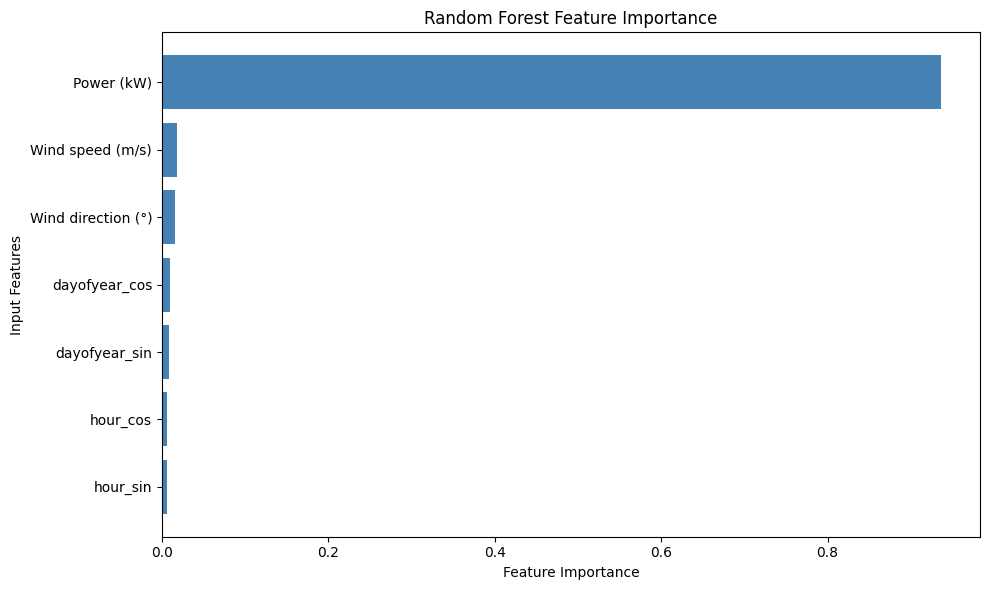

In [10]:
import matplotlib.pyplot as plt

# Extract feature importance scores
feature_importance_df = pd.DataFrame({
    "Feature": X_train_val.columns,
    "Importance": final_rf.feature_importances_
})

# Sort from highest to lowest importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("RANDOM FOREST FEATURE IMPORTANCE")
display(feature_importance_df.round(4))

# Plot feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Importance"],
    color="steelblue"
)

plt.gca().invert_yaxis()

plt.xlabel("Feature Importance")
plt.ylabel("Input Features")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

## Step 12: Actual vs Predicted Power Forecasts

Visualize the actual 30-minute-ahead power output alongside the Persistence Baseline and Random Forest predictions.

Plot the first 200 test observations for readability. This graph helps illustrate how closely each forecasting method follows the actual power output.

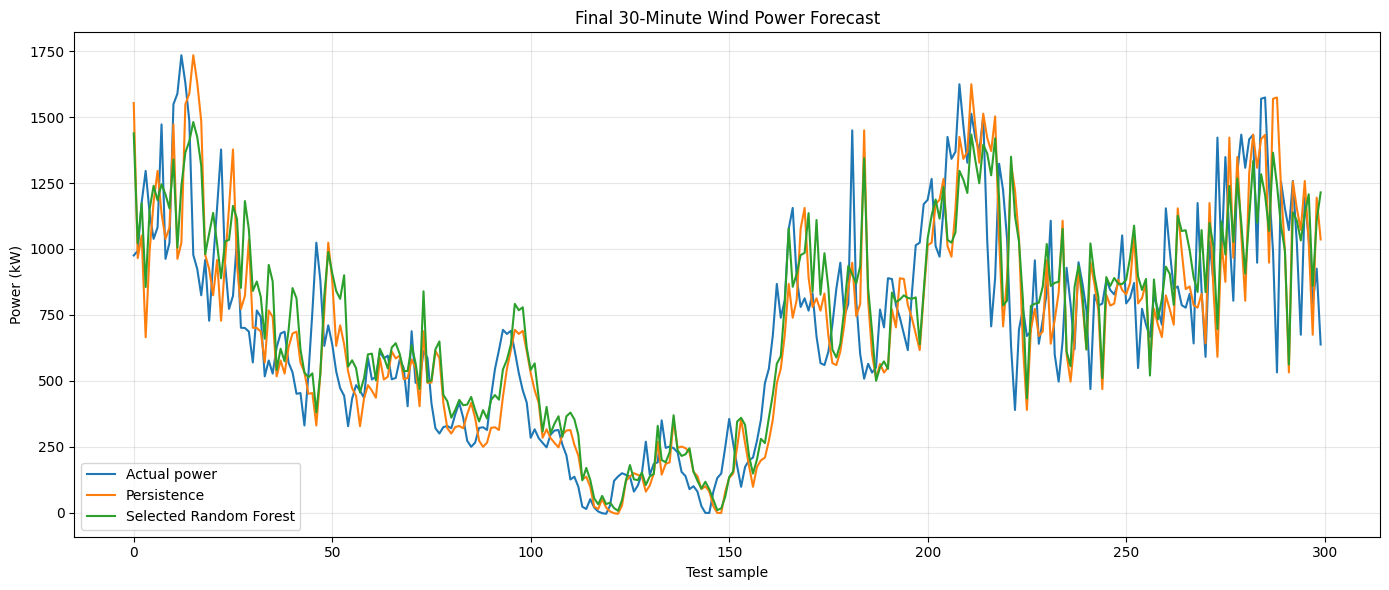

In [15]:
import matplotlib.pyplot as plt

# Plot first 300 test observations
n_plot = 300

plt.figure(figsize=(14, 6))

# Actual Power - Blue
plt.plot(
    y_test.iloc[:n_plot].to_numpy(),
    label="Actual power",
    color="#1f77b4",
    linewidth=1.5
)

# Persistence - Orange
plt.plot(
    persistence_pred[:n_plot],
    label="Persistence",
    color="#ff7f0e",
    linewidth=1.5
)

# Random Forest - Green
plt.plot(
    rf_test_pred[:n_plot],
    label="Selected Random Forest",
    color="#2ca02c",
    linewidth=1.5
)

plt.title("Final 30-Minute Wind Power Forecast")
plt.xlabel("Test sample")
plt.ylabel("Power (kW)")

plt.legend(loc="lower left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Step 13: Save Final Results and Visualizations

Export the validation results, final test metrics, feature importance scores, and forecast comparison plots.

These files provide reproducible evidence of model selection, performance, and interpretability.

In [16]:
import os
import matplotlib.pyplot as plt

# Create folder for final outputs
OUTPUT_DIR = "/content/results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save results as CSV files
validation_df.to_csv(
    os.path.join(OUTPUT_DIR, "validation_results.csv"),
    index=False
)

final_results.to_csv(
    os.path.join(OUTPUT_DIR, "final_test_results.csv"),
    index=False
)

feature_importance_df.to_csv(
    os.path.join(OUTPUT_DIR, "final_feature_importance.csv"),
    index=False
)

# Save feature importance graph
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Importance"],
    color="steelblue"
)

plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.ylabel("Input Features")
plt.title("Random Forest Feature Importance")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "final_feature_importance.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.close()

# Save forecast comparison graph
n_plot = 300

plt.figure(figsize=(14, 6))

plt.plot(
    y_test.iloc[:n_plot].to_numpy(),
    label="Actual power",
    color="#1f77b4",
    linewidth=1.5
)

plt.plot(
    persistence_pred[:n_plot],
    label="Persistence",
    color="#ff7f0e",
    linewidth=1.5
)

plt.plot(
    rf_test_pred[:n_plot],
    label="Selected Random Forest",
    color="#2ca02c",
    linewidth=1.5
)

plt.title("Final 30-Minute Wind Power Forecast")
plt.xlabel("Test sample")
plt.ylabel("Power (kW)")
plt.legend(loc="lower left")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "final_forecast_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.close()

# Verify saved files
print("FILES SAVED SUCCESSFULLY:\n")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(filename)

FILES SAVED SUCCESSFULLY:

final_feature_importance.csv
final_feature_importance.png
final_forecast_comparison.png
final_test_results.csv
validation_results.csv


## Step 14: Download Project Results

Package the final CSV results and visualization files into a ZIP archive for downloading and uploading to GitHub.

In [17]:
import shutil
from google.colab import files

# Create ZIP containing the five final result files
zip_path = shutil.make_archive(
    "/content/wind_forecasting_results",
    "zip",
    OUTPUT_DIR
)

print("ZIP created:", zip_path)

# Download ZIP to laptop
files.download(zip_path)

ZIP created: /content/wind_forecasting_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>